# This Project for me Learning How to code Polynomial Regression in Machine Learning 

## Import Library What We Need

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

## Load Dataset

In [2]:
df = pd.read_csv('../dataset/train_housePrices.csv')

## Data Understanding

In [3]:
df.shape

(1460, 81)

In [4]:
df.head(10)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000
6,7,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,307000
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
8,9,50,RM,51.0,6120,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900
9,10,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2008,WD,Normal,118000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [6]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


## Exploratory Data Analysis (EDA)

In [7]:
# Check Missing Value
print(df.isnull().sum().sort_values(ascending=False))

PoolQC           1453
MiscFeature      1406
Alley            1369
Fence            1179
MasVnrType        872
                 ... 
MoSold              0
YrSold              0
SaleType            0
SaleCondition       0
SalePrice           0
Length: 81, dtype: int64


In [8]:
# Check duplicate data
print(df.duplicated().sum())

0


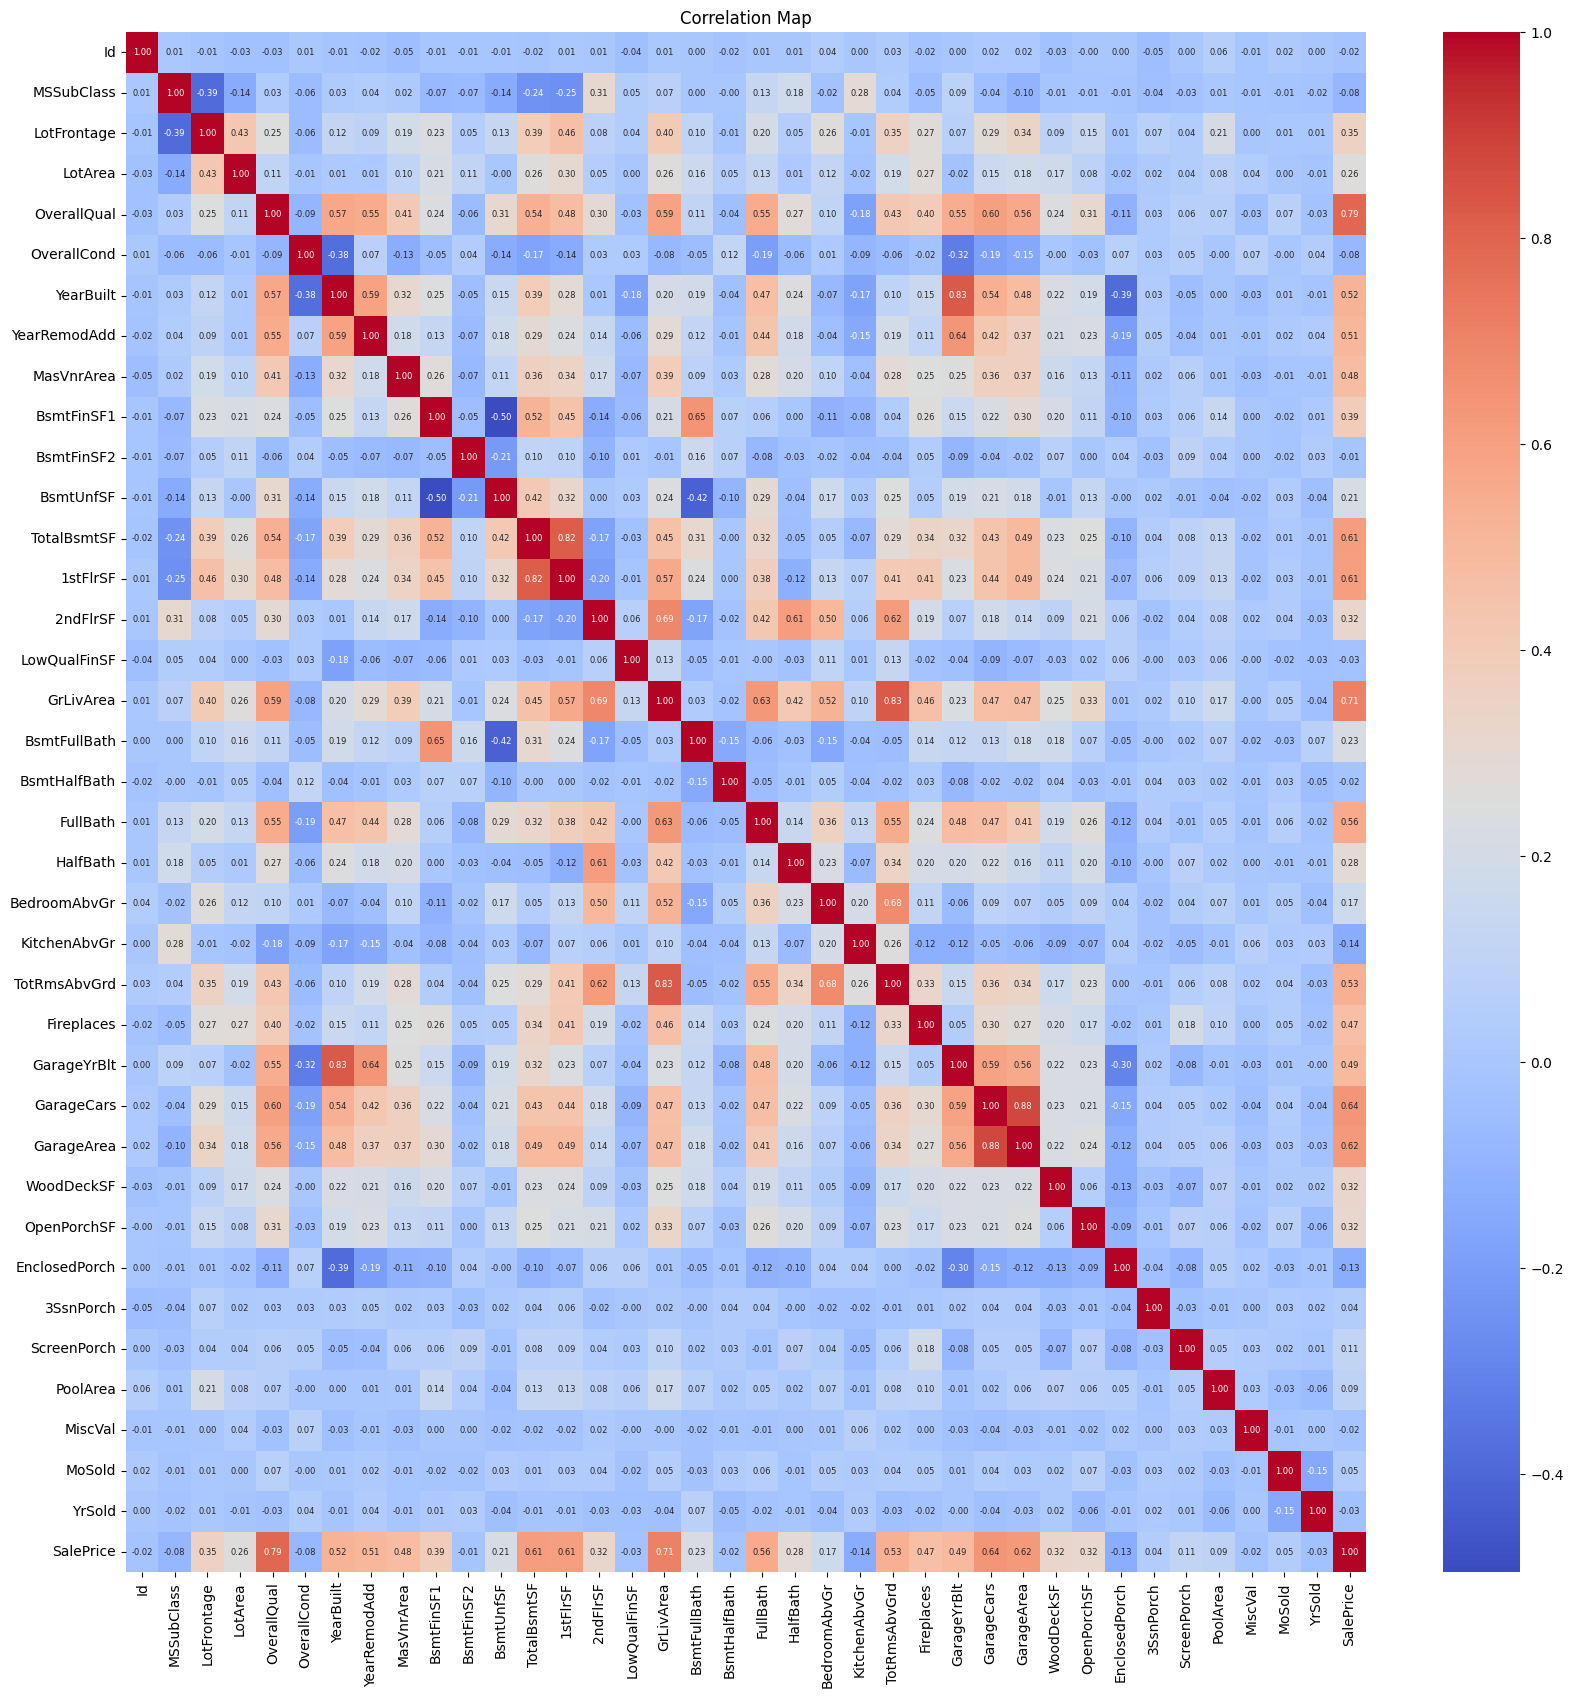

In [9]:
# Visulatization Correlation
corr = df.corr(numeric_only=True)
plt.figure(figsize=(20,20))
sns.heatmap(
    corr, 
    annot=True, 
    cmap="coolwarm",
    fmt=".2f",
    annot_kws={"size":6}
)
plt.title("Correlation Map")
plt.show()

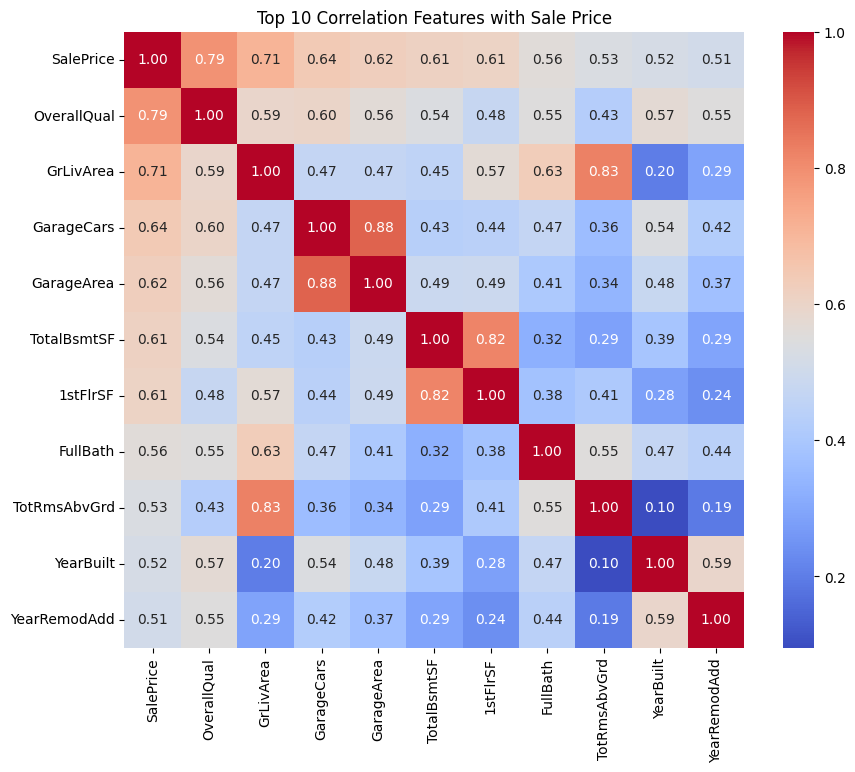

In [10]:
# Correlation map for top 10 Features
corr = df.corr(numeric_only=True)

top_corr = (
    corr['SalePrice']
    .abs()
    .sort_values(ascending=False)
    .head(11)
)

top_features = top_corr.index

plt.figure(figsize=(10,8))
sns.heatmap(
    corr.loc[top_features, top_features],
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title("Top 10 Correlation Features with Sale Price")
plt.show()

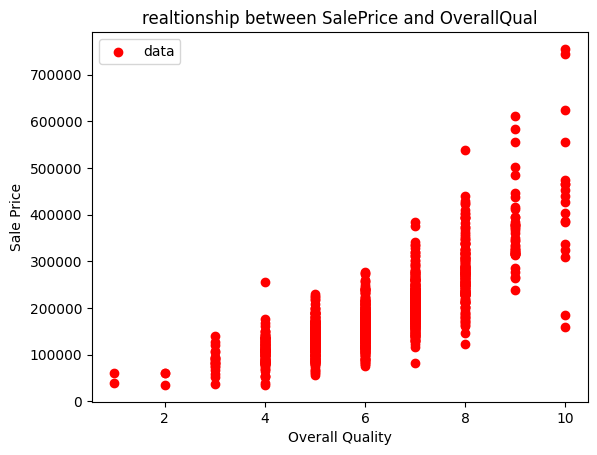

In [11]:
# Make Scatter Visualization
plt.scatter(x=df['OverallQual'], y=df['SalePrice'], color='red', label='data')
plt.xlabel('Overall Quality')
plt.ylabel("Sale Price")
plt.legend()
plt.title("realtionship between SalePrice and OverallQual")
plt.show()

# Conlucions
# We can see at visulization, relation between SP and AQ enough strong but we still can see outlier on 10 OQ and 700000 SP 

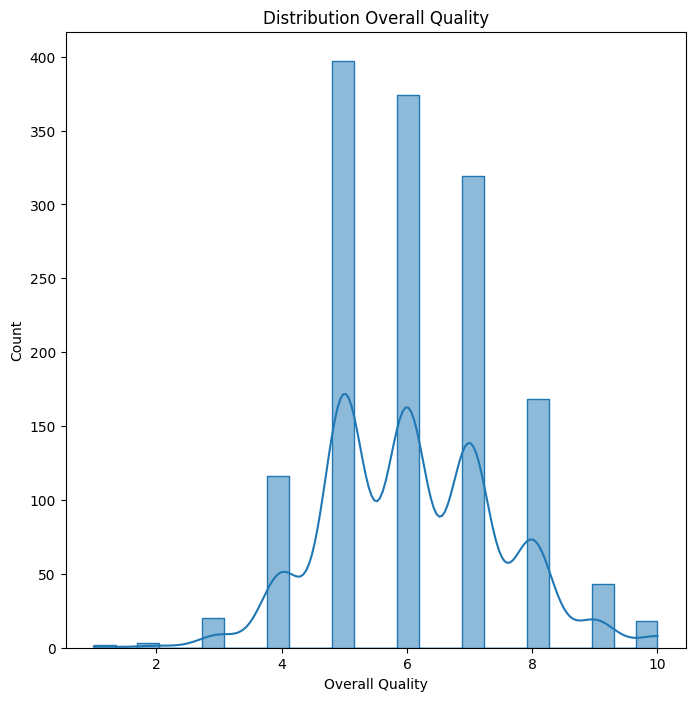

In [12]:
# Check Distribution X 
plt.figure(figsize=(8,8))
sns.histplot(data= df, x=df['OverallQual'], kde=True, element='step')
plt.xlabel("Overall Quality")
plt.ylabel("Count")
plt.title("Distribution Overall Quality")
plt.show()


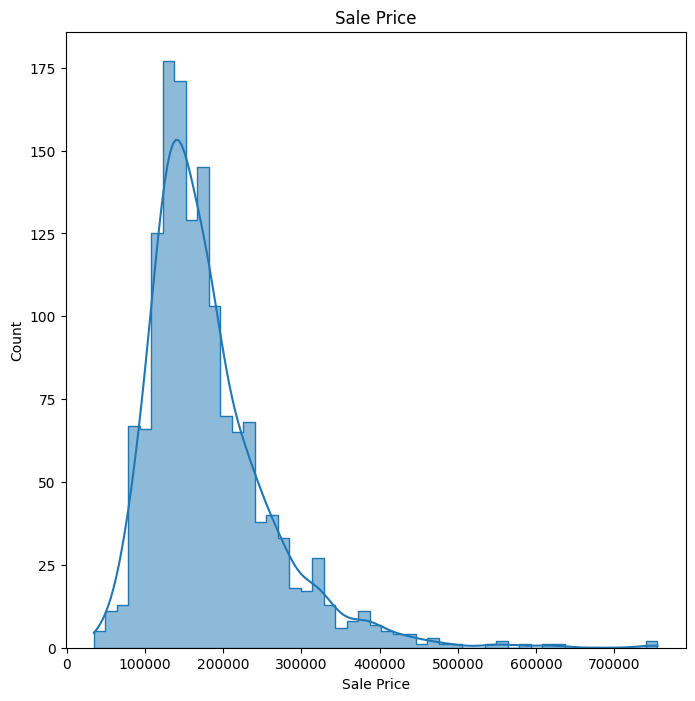

In [13]:
# Check Distribution y 
plt.figure(figsize=(8,8))
sns.histplot(data= df, x=df['SalePrice'], kde=True, element='step')
plt.xlabel("Sale Price")
plt.ylabel("Count")
plt.title("Sale Price")
plt.show()

C:\Users\ROG\AppData\Local\Temp\ipykernel_29016\3297588854.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


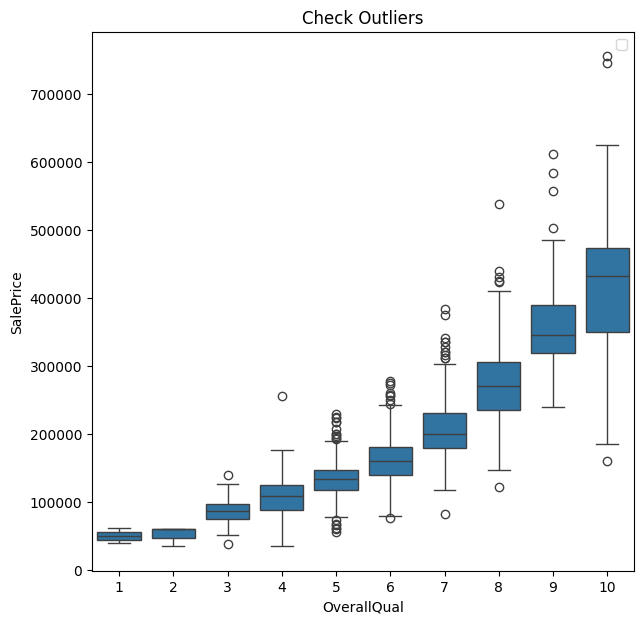

In [14]:
# We gonna check outliers between SP and OQ
plt.figure(figsize=(7,7))
sns.boxplot(data= df, x=df['OverallQual'],y=df['SalePrice'])
plt.title("Check Outliers")
plt.legend()
plt.show()

## Data Cleaning
### We gonna drop coloumn
- PoolQC           1453
- MiscFeature      1406
- Alley            1369
- Fence            1179
Because the missing value > 50%, so i decide to drop them, and we can see at corr map they're not in 10 features strongest

In [15]:
# Drop Coloumn
df = df.drop('PoolQC', axis=1)
df = df.drop('MiscFeature', axis=1)
df = df.drop('Alley', axis=1)
df = df.drop('Fence', axis=1)

print("Drop Column Success")

Drop Column Success


In [16]:
# Check missing value after drop coloumn
print(df.isnull().sum().sort_values(ascending=False).to_string())

MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageFinish      81
GarageQual        81
GarageCond        81
GarageType        81
GarageYrBlt       81
BsmtExposure      38
BsmtFinType2      38
BsmtCond          37
BsmtFinType1      37
BsmtQual          37
MasVnrArea         8
Electrical         1
LandSlope          0
LotConfig          0
Condition1         0
Neighborhood       0
LotShape           0
Street             0
LotArea            0
MSZoning           0
MSSubClass         0
Id                 0
Utilities          0
LandContour        0
RoofStyle          0
YearRemodAdd       0
Foundation         0
ExterCond          0
ExterQual          0
Exterior2nd        0
RoofMatl           0
Exterior1st        0
BsmtFinSF2         0
BsmtFinSF1         0
BsmtUnfSF          0
TotalBsmtSF        0
Condition2         0
BldgType           0
OverallCond        0
YearBuilt          0
HouseStyle         0
OverallQual        0
LowQualFinSF       0
2ndFlrSF           0
1stFlrSF     

In [17]:
# i will fill MasVnrType with None, because this coloumn might be use later
df['MasVnrType'] = df['MasVnrType'].fillna('None')
print("Fill Succes")

# Check Missing Value :
print(df.isnull().sum().sort_values(ascending=False).to_string())

Fill Succes
FireplaceQu      690
LotFrontage      259
GarageFinish      81
GarageYrBlt       81
GarageQual        81
GarageCond        81
GarageType        81
BsmtExposure      38
BsmtFinType2      38
BsmtCond          37
BsmtQual          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
Neighborhood       0
LandSlope          0
LotConfig          0
Condition1         0
LandContour        0
LotShape           0
Street             0
LotArea            0
MSZoning           0
MSSubClass         0
Id                 0
Utilities          0
RoofMatl           0
RoofStyle          0
Condition2         0
Foundation         0
ExterCond          0
ExterQual          0
MasVnrType         0
Exterior1st        0
Exterior2nd        0
BsmtFinSF2         0
BsmtFinSF1         0
BsmtUnfSF          0
TotalBsmtSF        0
HouseStyle         0
BldgType           0
OverallCond        0
YearBuilt          0
YearRemodAdd       0
OverallQual        0
LowQualFinSF       0
2ndFlrSF           0
1

## Data Handling
because we have other coloumn with missing value but < 50%, so i will fill those coloumn with any metode

In [18]:
# These coloumn will be fill with None because these coloumn is Categorical
cols_none =[
    "FireplaceQu",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "GarageType",
    "BsmtExposure",
    "BsmtCond",
    "BsmtQual",
    "BsmtFinType1",
    "BsmtFinType2"
]
df[cols_none] = df[cols_none].fillna('None')
print("Fill Success")

print(df.isnull().sum().sort_values(ascending=False).to_string())

Fill Success
LotFrontage      259
GarageYrBlt       81
MasVnrArea         8
Electrical         1
Id                 0
Street             0
LotShape           0
LandContour        0
Utilities          0
LotConfig          0
MSSubClass         0
MSZoning           0
LotArea            0
Condition1         0
Neighborhood       0
LandSlope          0
HouseStyle         0
OverallCond        0
YearBuilt          0
YearRemodAdd       0
Condition2         0
RoofStyle          0
RoofMatl           0
Exterior2nd        0
Exterior1st        0
MasVnrType         0
ExterQual          0
ExterCond          0
BldgType           0
Foundation         0
BsmtQual           0
BsmtExposure       0
BsmtCond           0
BsmtFinSF1         0
BsmtFinType2       0
BsmtFinSF2         0
BsmtFinType1       0
BsmtUnfSF          0
TotalBsmtSF        0
HeatingQC          0
Heating            0
CentralAir         0
1stFlrSF           0
2ndFlrSF           0
OverallQual        0
LowQualFinSF       0
GrLivArea          0


In [19]:
# coloumn LotFrontage will be fill with groupby Neighborhood and median
df['LotFrontage'] = (
    df.groupby('Neighborhood')['LotFrontage']
    .transform(lambda x: x.fillna(x.median())))
print("Median Fill Success\n")
print(df.isnull().sum().sort_values(ascending=False).to_string())

Median Fill Success

GarageYrBlt      81
MasVnrArea        8
Electrical        1
MSSubClass        0
Id                0
Street            0
LotShape          0
LandContour       0
Utilities         0
LotConfig         0
MSZoning          0
LotFrontage       0
LotArea           0
Condition1        0
Neighborhood      0
LandSlope         0
HouseStyle        0
OverallCond       0
YearBuilt         0
YearRemodAdd      0
Condition2        0
RoofStyle         0
RoofMatl          0
Exterior2nd       0
Exterior1st       0
MasVnrType        0
ExterQual         0
ExterCond         0
BldgType          0
Foundation        0
BsmtQual          0
BsmtExposure      0
BsmtCond          0
BsmtFinSF1        0
BsmtFinType2      0
BsmtFinSF2        0
BsmtFinType1      0
BsmtUnfSF         0
TotalBsmtSF       0
HeatingQC         0
Heating           0
CentralAir        0
1stFlrSF          0
2ndFlrSF          0
OverallQual       0
LowQualFinSF      0
GrLivArea         0
BsmtHalfBath      0
BsmtFullBath      0

In [20]:
# Coloumn GarageYrBlt will be fill with 0 because i assume if NaN in this coloumn its mean 0 garage
df['GarageYrBlt'] = df['GarageYrBlt'].fillna(0)
print("Fill Success")

Fill Success


In [21]:
# Coloumn MasVnrArea will be fill with 0
df['MasVnrArea'] = df['MasVnrArea'].fillna(0)
print("Fill Success")

Fill Success


In [22]:
# Coloumn Electrical Mode
df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])
print("Fill Success")

Fill Success


In [23]:
# Check Missing Value after we handling those data
print(df.isnull().sum().sort_values(ascending=False).to_string())

Id               0
MSSubClass       0
MSZoning         0
LotFrontage      0
LotArea          0
Street           0
LotShape         0
LandContour      0
Utilities        0
LotConfig        0
LandSlope        0
Neighborhood     0
Condition1       0
Condition2       0
BldgType         0
HouseStyle       0
OverallQual      0
OverallCond      0
YearBuilt        0
YearRemodAdd     0
RoofStyle        0
RoofMatl         0
Exterior1st      0
Exterior2nd      0
MasVnrType       0
MasVnrArea       0
ExterQual        0
ExterCond        0
Foundation       0
BsmtQual         0
BsmtCond         0
BsmtExposure     0
BsmtFinType1     0
BsmtFinSF1       0
BsmtFinType2     0
BsmtFinSF2       0
BsmtUnfSF        0
TotalBsmtSF      0
Heating          0
HeatingQC        0
CentralAir       0
Electrical       0
1stFlrSF         0
2ndFlrSF         0
LowQualFinSF     0
GrLivArea        0
BsmtFullBath     0
BsmtHalfBath     0
FullBath         0
HalfBath         0
BedroomAbvGr     0
KitchenAbvGr     0
KitchenQual 

## Splitting Data first model

In [24]:
# Import Library
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures

# Feature Selection
X = df[['OverallQual']]
y = df['SalePrice']

# Spliitting data
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=42
)

## Train model and Evaluation

In [25]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# Transform Features to polynomial features
degrees = [1, 2, 3, 4, 5]

# Save Model and Prediction Result
models = {}
residual_dict = {}

# for dataframe
result = []



# Looping for all degrees
for degree in degrees :
    poly_feature = PolynomialFeatures(degree=degree, include_bias=False)
    X_train_poly = poly_feature.fit_transform(X_train)
    X_test_poly = poly_feature.transform(X_test)
 
    # Linear Regression
    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    
    # Prediction
    y_predic = model.predict(X_test_poly)

    # Residual
    residual = y_test - y_predic

    # Saving residual result 
    residual_dict[degree] = residual

    # Print mean residual
    # print(f'Mean Residual degree {degree} : {residual.mean()}')

    mean_residual = residual.mean()

    # Print Residual
    # print(f'Residual degree : {residual}')
    # print('\n')

    # Evaluation per degrees
    p_mae = mean_absolute_error(y_test, y_predic)
    p_rmse = np.sqrt(mean_squared_error(y_test, y_predic))
    p_r2 = r2_score(y_test, y_predic)

    # Print Evaluation
    result.append({
        'Degree' : degree,
        'Mean Residual' : mean_residual,
        'MAE' : p_mae,
        'RMSE' : p_rmse,
        'R2' : p_r2
    })


    # Saving Model and Polynomial Transform
    models[degree] ={
        'poly' : poly_feature,
        'model' : model,
        'y prediction' : y_predic
    }
result_df = pd.DataFrame(result)
print(result_df)


   Degree  Mean Residual           MAE          RMSE        R2
0       1    2337.810871  33343.242087  51778.626512  0.650468
1       2     790.927582  30359.830274  46635.775926  0.716453
2       3     618.513582  30009.260639  46134.152109  0.722520
3       4     497.969291  30106.635003  46291.310877  0.720627
4       5     647.487219  30021.745488  46371.772324  0.719655


# Visualization Residual

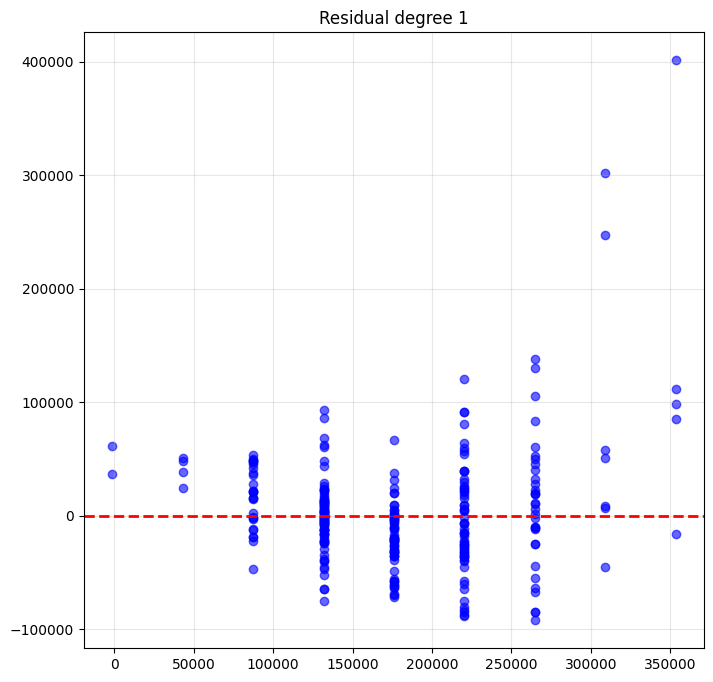

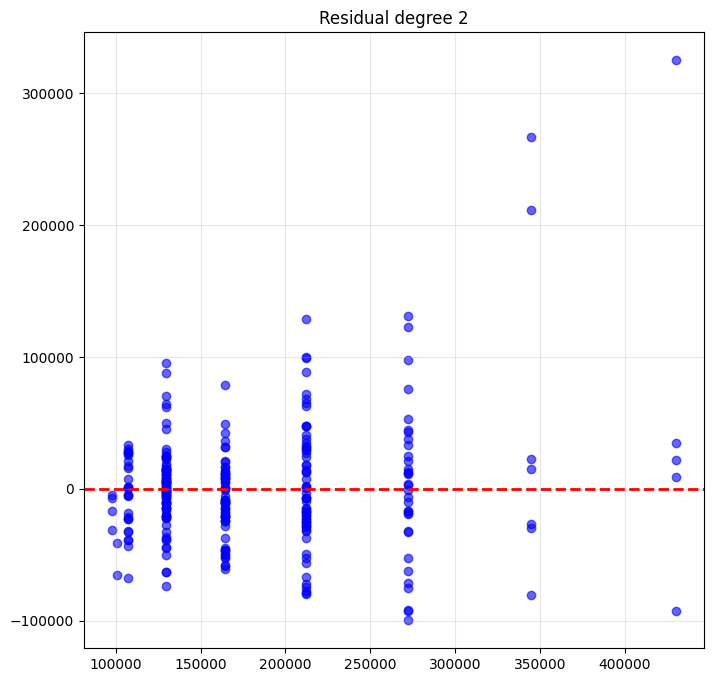

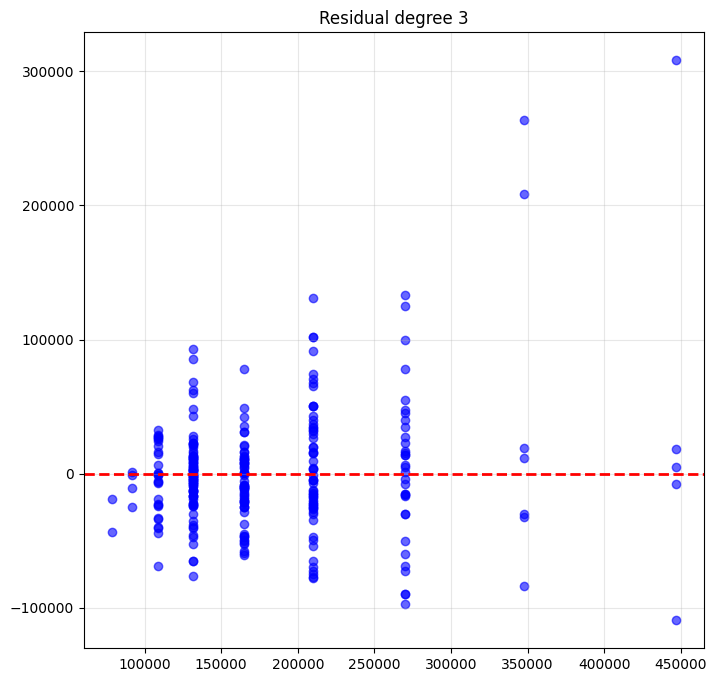

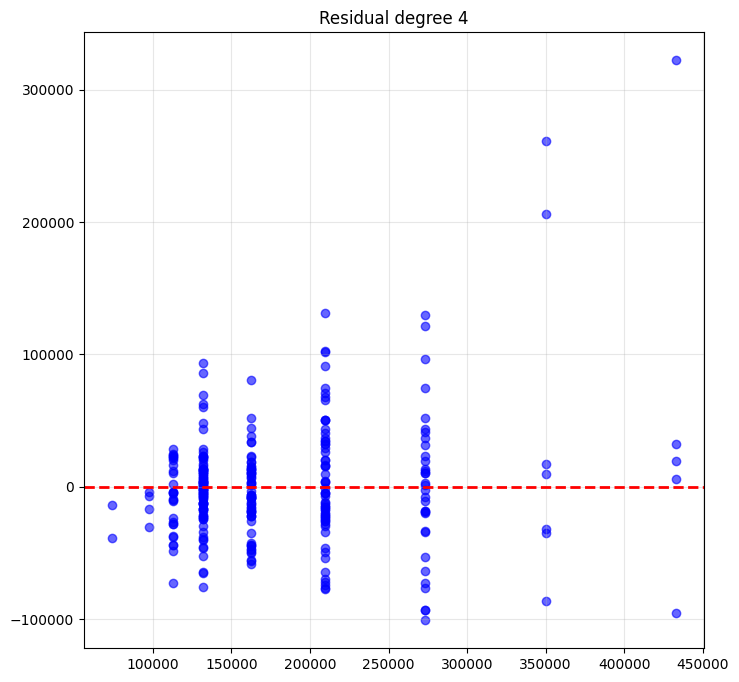

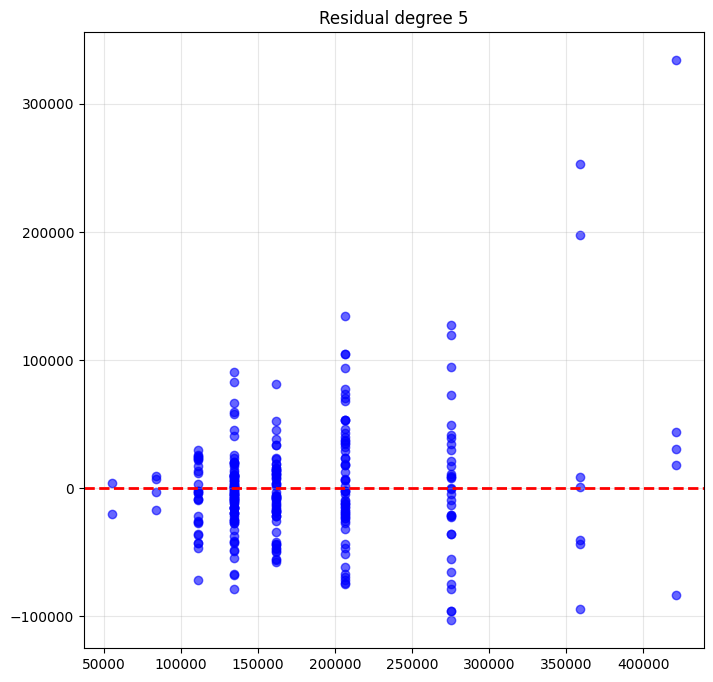

In [34]:
for degree in degrees :
    y_pred = models[degree]['y prediction']
    residual = residual_dict[degree]

    plt.figure(figsize=(8,8))
    plt.scatter(y_pred, residual, color='blue', alpha=0.6)
    plt.axhline(0, color='red', linestyle='--', linewidth=2)
    plt.title(f"Residual degree {degree}")
    plt.grid(alpha=0.3)
    plt.show

# Visualization Polynomial

c:\Users\ROG\anaconda3\envs\deep_learning\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
c:\Users\ROG\anaconda3\envs\deep_learning\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
c:\Users\ROG\anaconda3\envs\deep_learning\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
c:\Users\ROG\anaconda3\envs\deep_learning\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
c:\Users\ROG\anaconda3\envs\deep_learning\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, 

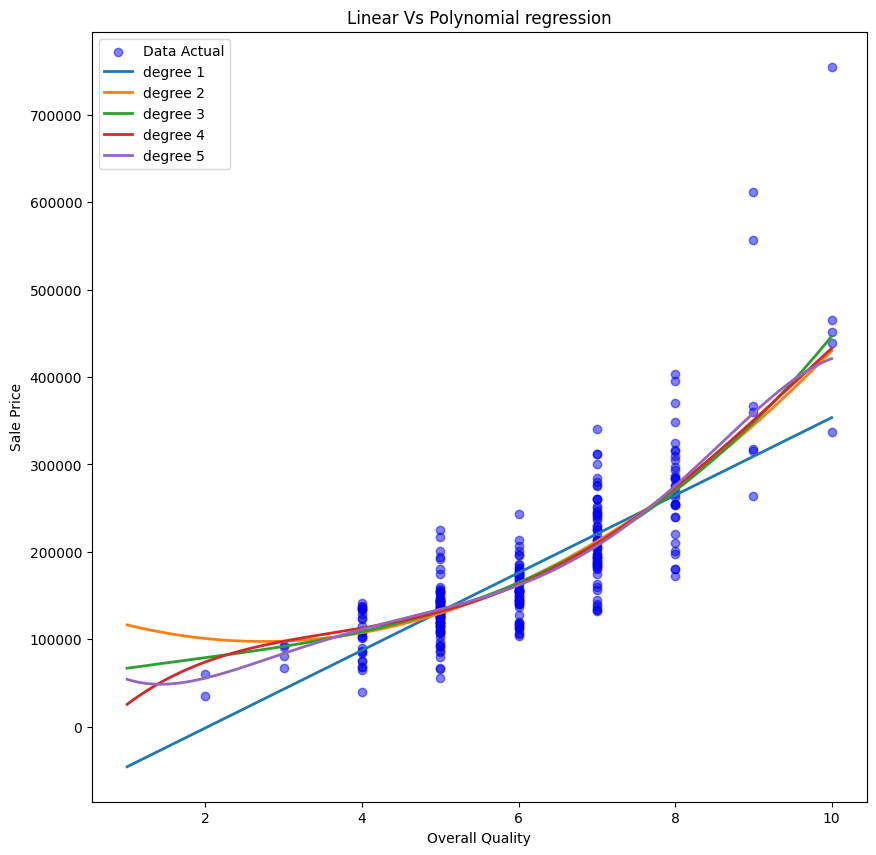

In [26]:
X_range = np.linspace(
    X['OverallQual'].min(),
    X['OverallQual'].max(),
    3000
).reshape(-1,1)

plt.figure(figsize=(10,10))

# Data Actual
plt.scatter(X_test, y_test, color='blue', alpha= 0.5 ,label='Data Actual')

# Data degree
for degree in degrees :
    poly = models[degree]['poly']
    model = models[degree]['model']

    # Transform X_range
    X_range_poly = poly.transform(X_range)

    # Prediction
    y_range_pred = model.predict(X_range_poly)

    # plot curve
    plt.plot(
        X_range,
        y_range_pred,
        linewidth = 2,
        label=f'degree {degree}'
    )

plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")
plt.title('Linear Vs Polynomial regression')
plt.legend()
plt.show()

c:\Users\ROG\anaconda3\envs\deep_learning\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
c:\Users\ROG\anaconda3\envs\deep_learning\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


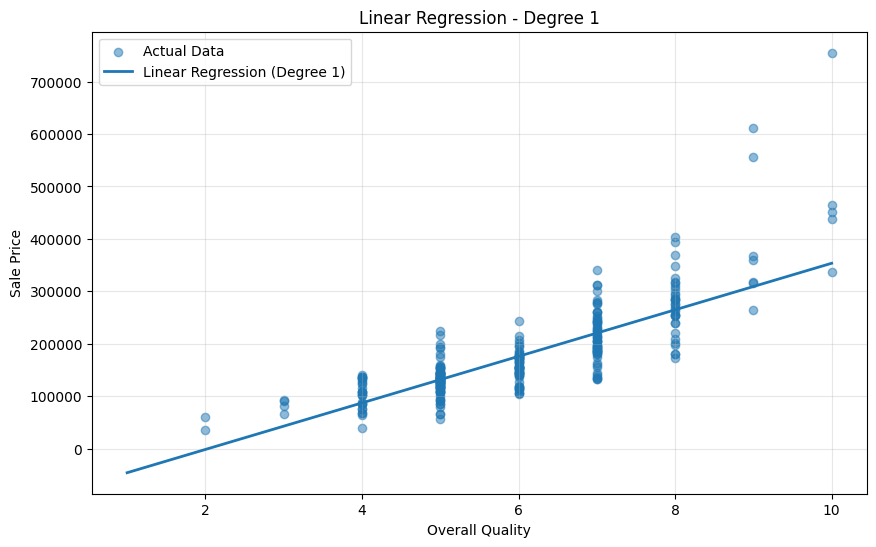

c:\Users\ROG\anaconda3\envs\deep_learning\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


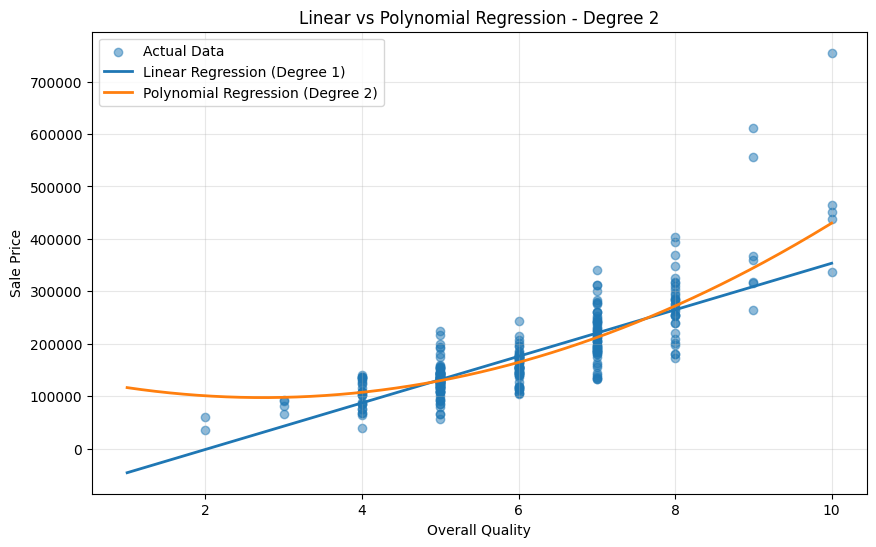

c:\Users\ROG\anaconda3\envs\deep_learning\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


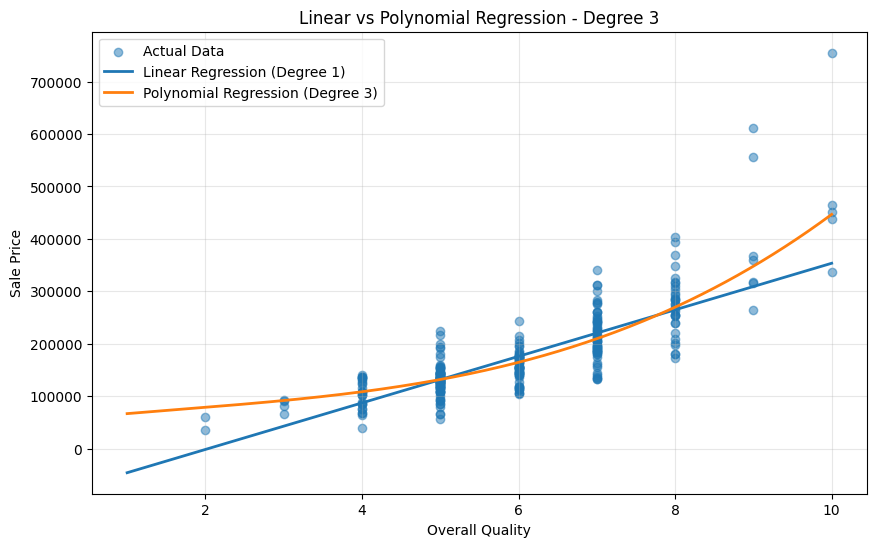

c:\Users\ROG\anaconda3\envs\deep_learning\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


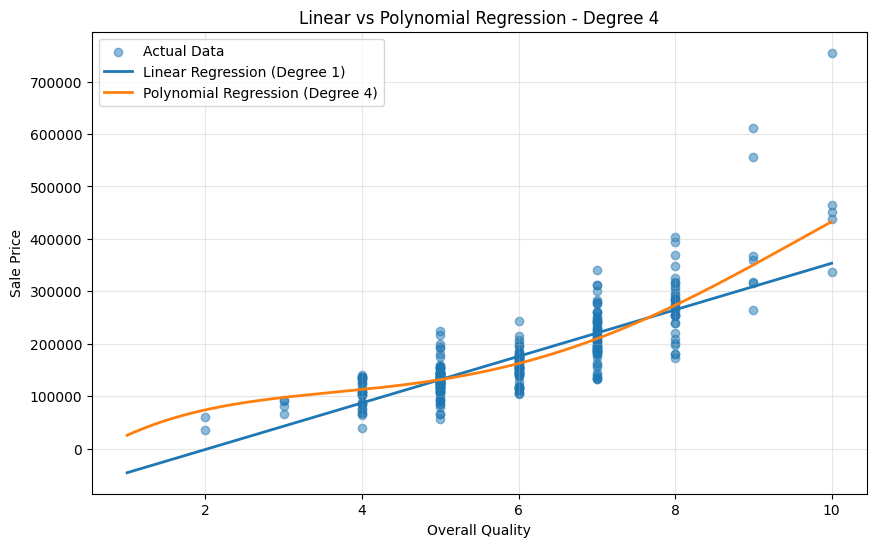

c:\Users\ROG\anaconda3\envs\deep_learning\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


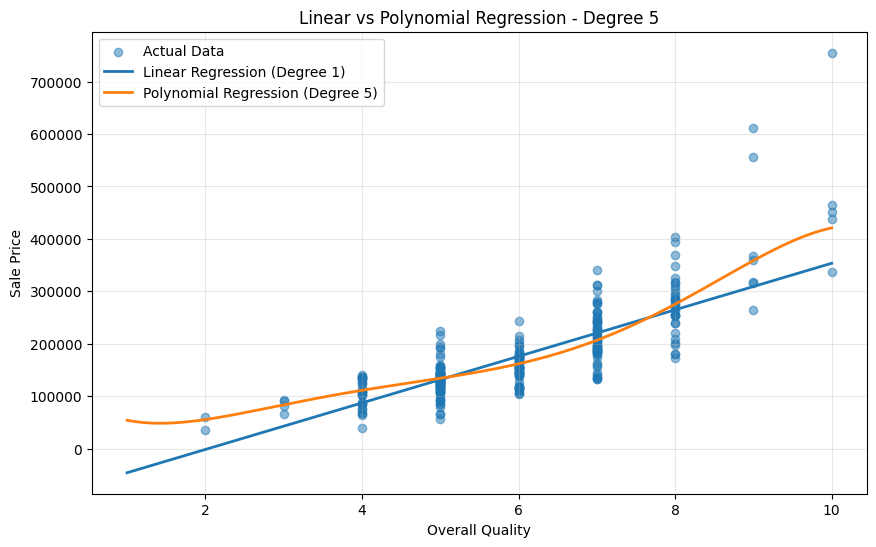

In [27]:
# X range for smooth line
X_range = np.linspace(
    X['OverallQual'].min(),
    X['OverallQual'].max(),
    300
).reshape(-1, 1)


# Degree1
linear_poly = models[1]['poly']
linear_model = models[1]['model']

X_range_linear = linear_poly.transform(X_range)
y_range_linear = linear_model.predict(X_range_linear)

# Visualisasi Setiap degree
for degree in degrees:

    # Ambil transformer dan model
    poly = models[degree]['poly']
    model = models[degree]['model']

    # Transform X_range
    X_range_poly = poly.transform(X_range)

    # Prediction
    y_range_poly = model.predict(X_range_poly)

    # make figure
    plt.figure(figsize=(10, 6))

    # Actual Data
    plt.scatter(
        X_test,
        y_test,
        alpha=0.5,
        label='Actual Data'
    )
    # DEGREE 1
    if degree == 1:
        plt.plot(
            X_range,
            y_range_linear,
            linewidth=2,
            label='Linear Regression (Degree 1)'
        )

    # DEGREE 2 - 5
    else:
        # Linear Regression sebagai baseline
        plt.plot(
            X_range,
            y_range_linear,
            linewidth=2,
            label='Linear Regression (Degree 1)'
        )
        # Polynomial Regression
        plt.plot(
            X_range,
            y_range_poly,
            linewidth=2,
            label=f'Polynomial Regression (Degree {degree})'
        )
        
    if degree == 1:
        plt.title('Linear Regression - Degree 1')
    else:
        plt.title(
            f'Linear vs Polynomial Regression - Degree {degree}'
        )

    plt.xlabel('Overall Quality')
    plt.ylabel('Sale Price')

    plt.legend()
    plt.grid(alpha=0.3)

    plt.show()

# Result
After training and evaluation, we can determine if degree three is the best fit for this case. This is because the MSE and RMSE are lower than the other degrees, and the R2 is higher than the other degrees.